In [ ]:
"""understanding the data"""
#importing python libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#loading a student dataset 
df=pd.read_csv('student_data.csv')
#displaying the first 5 rows of the dataset
print(df.head())

  Student_ID   Student_Name  Study_Hours_Per_Day  Attendance_Percent  \
0    STU0001  Nandini Joshi                  1.2                  72   
1    STU0002    Yash Kapoor                  3.9                  87   
2    STU0003  Madhav Mishra                  4.6                  86   
3    STU0004    Kavya Joshi                  3.7                  88   
4    STU0005      Divya Rao                  0.6                  88   

   Math_Score  Science_Score  English_Score  
0          75             64             61  
1          76             63             89  
2          77             79             73  
3          77             93             79  
4          39             49             55  


In [2]:
#for data analysis , we will check the shape of the dataset, data types of each column, and missing values in the dataset.
#checking the no of rows and columns in the dataset
print("Shape of the dataset:", df.shape)
#displaying column names
print("Column names:", df.columns.tolist())
#to check datatypes,missing values 
print("dataset info:")
print(df.info())
#to print the summary statistics of the dataset
print("Summary statistics of the dataset:")
print(df.describe())


Shape of the dataset: (500, 7)
Column names: ['Student_ID', 'Student_Name', 'Study_Hours_Per_Day', 'Attendance_Percent', 'Math_Score', 'Science_Score', 'English_Score']
dataset info:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Student_ID           500 non-null    str    
 1   Student_Name         500 non-null    str    
 2   Study_Hours_Per_Day  500 non-null    float64
 3   Attendance_Percent   500 non-null    int64  
 4   Math_Score           500 non-null    int64  
 5   Science_Score        500 non-null    int64  
 6   English_Score        500 non-null    int64  
dtypes: float64(1), int64(4), str(2)
memory usage: 27.5 KB
None
Summary statistics of the dataset:
       Study_Hours_Per_Day  Attendance_Percent  Math_Score  Science_Score  \
count           500.000000          500.000000    500.0000     500.000000   
mean              3.8

In [3]:
# for checking missing values in the dataset 
print("missing values:")
print(df.isnull().sum())
#checking duplicate rows in the dataset
print("number of duplicate rows:")
print(df.duplicated().sum())
#checking the shape of dataset 
print("dataset shape",df.shape)

missing values:
Student_ID             0
Student_Name           0
Study_Hours_Per_Day    0
Attendance_Percent     0
Math_Score             0
Science_Score          0
English_Score          0
dtype: int64
number of duplicate rows:
0
dataset shape (500, 7)


In [5]:
# view dataset 
df.head()


,Student_ID,Student_Name,Study_Hours_Per_Day,Attendance_Percent,Math_Score,Science_Score,English_Score
0,STU0001,Nandini Joshi,1.2,72,75,64,61
1,STU0002,Yash Kapoor,3.9,87,76,63,89
2,STU0003,Madhav Mishra,4.6,86,77,79,73
3,STU0004,Kavya Joshi,3.7,88,77,93,79
4,STU0005,Divya Rao,0.6,88,39,49,55


In [6]:
# check numerical statstics 
df.describe()

,Study_Hours_Per_Day,Attendance_Percent,Math_Score,Science_Score,English_Score
count,500.000000,500.000000,500.0000,500.000000,500.000000
mean,3.836400,80.642000,68.4400,70.296000,72.156000
std,1.516018,10.491233,14.4334,15.183988,12.553679
min,0.300000,49.000000,32.0000,19.000000,33.000000
25%,2.800000,74.000000,59.0000,59.750000,64.000000
50%,3.800000,81.000000,68.0000,71.000000,72.000000
75%,4.800000,88.000000,78.0000,81.000000,82.000000
max,8.100000,100.000000,100.0000,100.000000,100.000000


In [7]:
#check the columns
df.columns

Index(['Student_ID', 'Student_Name', 'Study_Hours_Per_Day',
       'Attendance_Percent', 'Math_Score', 'Science_Score', 'English_Score'],
      dtype='str')

In [8]:
print(df.columns.tolist())


['Student_ID', 'Student_Name', 'Study_Hours_Per_Day', 'Attendance_Percent', 'Math_Score', 'Science_Score', 'English_Score']


In [11]:
# score analysis  distribution 
#calculating mean for math_score
print("mean:",df["Math_Score"].mean())
#calcualting median for math_score
print("median:",df["Math_Score"].median())
#calculating standard deviation 
print("standard deviation:",df["Math_Score"].std())
#calculating skewness 
print("skewness:",df["Math_Score"].skew())


mean: 68.44
median: 68.0
standard deviation: 14.433400364854581
skewness: -0.07401704393511706


In [14]:
#analysing student performance_level
bins=[0,35,50,70,85,100]
labels=["fail","pass","average","good","excellent"]
df["performance_level"]=pd.cut(
    df["Math_Score"],
    bins=bins,
    labels=labels,
    include_lowest=True
)
print(df["performance_level"].value_counts().sort_index())

performance_level
fail           6
pass          47
average      226
good         152
excellent     69
Name: count, dtype: int64


In [16]:
#to understand relation between the subjects
subjects=["Math_Score","Science_Score","English_Score"]
#calculating correlation between the subjects
print(df[subjects].corr())

               Math_Score  Science_Score  English_Score
Math_Score       1.000000       0.257837       0.243551
Science_Score    0.257837       1.000000       0.212958
English_Score    0.243551       0.212958       1.000000


In [22]:
#identifying the outliers in scores in each subject 
#outliers in math_score
column="Math_Score"
Q1=df[column].quantile(0.25)
Q3=df[column].quantile(0.75)
#interquartile range 
IQR=Q3-Q1
#calculating upper and lower limits 
lower_limit=Q1-1.5*IQR
upper_limit=Q3+1.5*IQR
#calculating outliers
outliers=df[
        (df[column]<lower_limit)|
         (df[column]>upper_limit)
]
print("outliers",len(outliers))


outliers 0


In [23]:
#identifying the outliers in scores in each subject 
#outliers in Science_Score
column="Science_Score"
Q1=df[column].quantile(0.25)
Q3=df[column].quantile(0.75)
#interquartile range 
IQR=Q3-Q1
#calculating upper and lower limits 
lower_limit=Q1-1.5*IQR
upper_limit=Q3+1.5*IQR
#calculating outliers
outliers=df[
        (df[column]<lower_limit)|
         (df[column]>upper_limit)
]
print("outliers",len(outliers))

outliers 1


In [24]:
#identifying the outliers in scores in each subject 
#outliers in English_Score
column="English_Score"
Q1=df[column].quantile(0.25)
Q3=df[column].quantile(0.75)
#interquartile range 
IQR=Q3-Q1
#calculating upper and lower limits 
lower_limit=Q1-1.5*IQR
upper_limit=Q3+1.5*IQR
#calculating outliers
outliers=df[
        (df[column]<lower_limit)|
         (df[column]>upper_limit)
]
print("outliers",len(outliers))

outliers 2


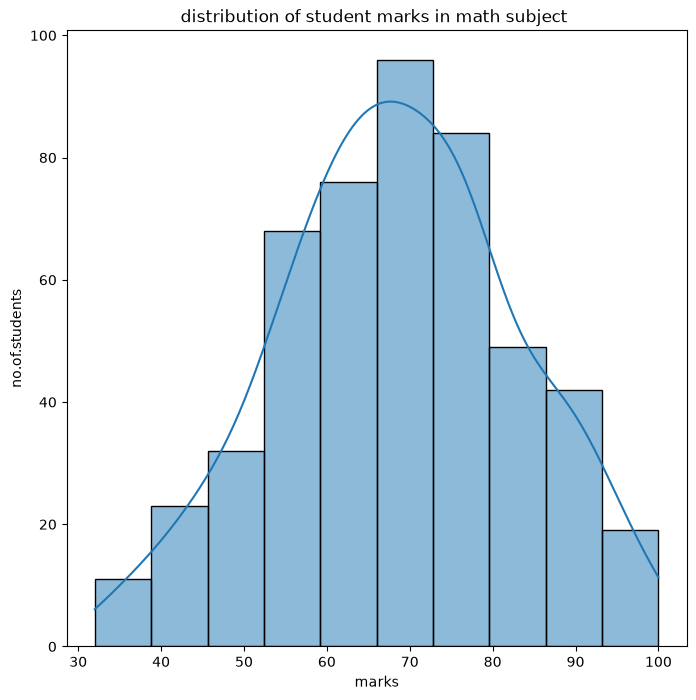

In [ ]:
"""data visualization """
#overall marks distribution for maths subject 
plt.figure(figsize=(8,8))
sns.histplot(data=df,x="Math_Score",bins=10,kde=True)
plt.title("distribution of student marks in math subject ")
plt.xlabel("marks")
plt.ylabel("no.of.students")
plt.show()

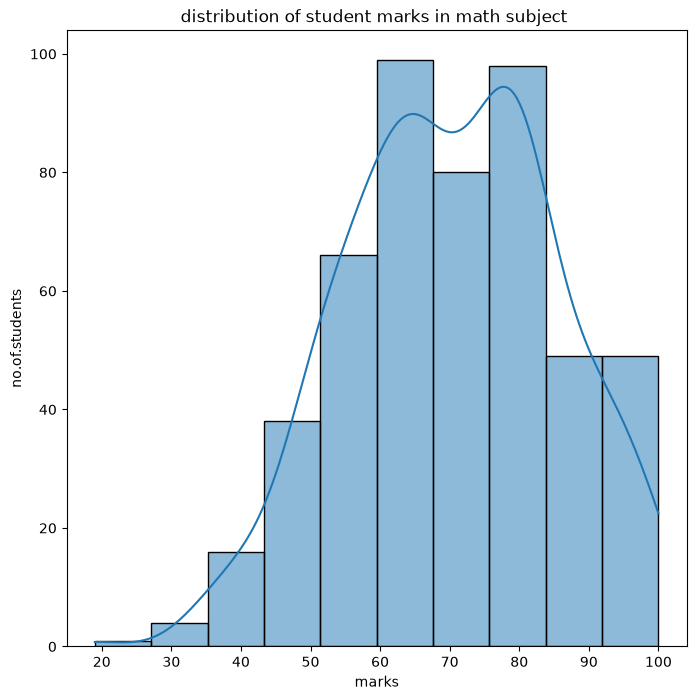

In [29]:
"""data visualization """
#overall marks distribution for Science subject 
plt.figure(figsize=(8,8))
sns.histplot(data=df,x="Science_Score",bins=10,kde=True)
plt.title("distribution of student marks in math subject ")
plt.xlabel("marks")
plt.ylabel("no.of.students")
plt.show()

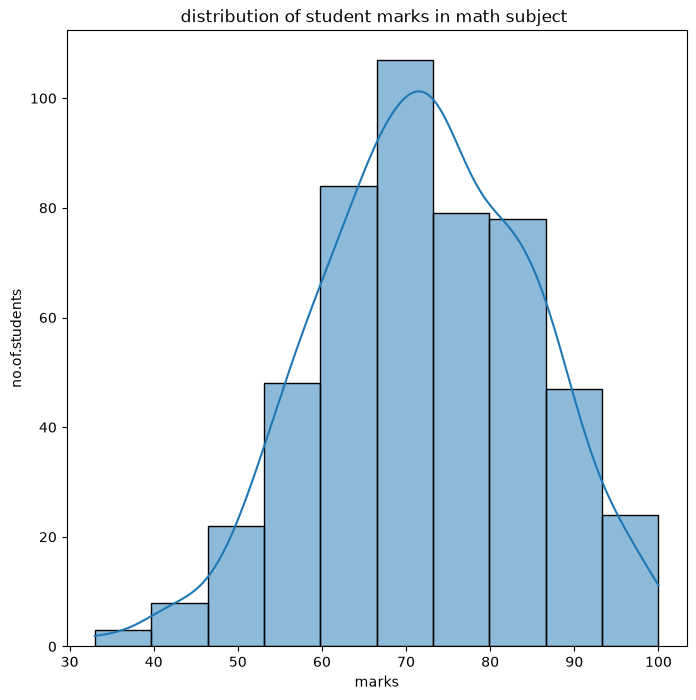

In [30]:
"""data visualization """
#overall marks distribution for english subject 
plt.figure(figsize=(8,8))
sns.histplot(data=df,x="English_Score",bins=10,kde=True)
plt.title("distribution of student marks in math subject ")
plt.xlabel("marks")
plt.ylabel("no.of.students")
plt.show()

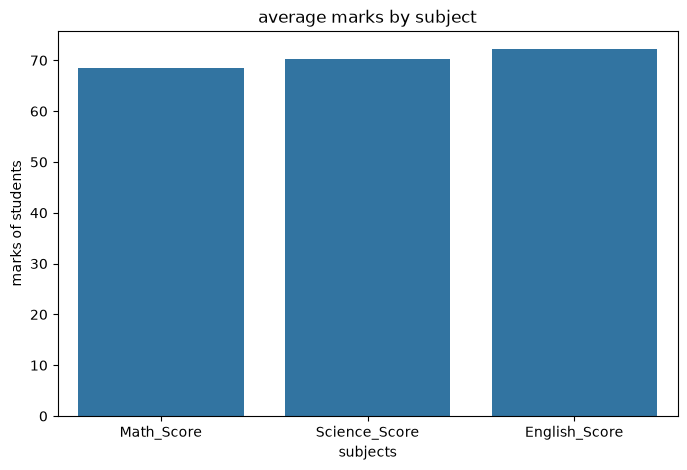

In [31]:
"""average marks by subject """
subjects=["Math_Score","Science_Score","English_Score"]
avg_marks=df[subjects].mean()
plt.figure(figsize=(8,5))
sns.barplot(x=avg_marks.index,y=avg_marks.values)
plt.title("average marks by subject")
plt.xlabel("subjects")
plt.ylabel("marks of students")
plt.show()

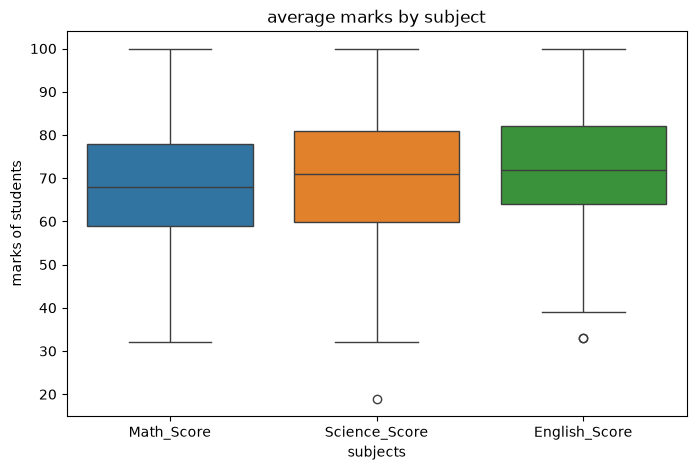

In [32]:
"""score variation by subject """
plt.figure(figsize=(8,5))
sns.boxplot(data=df[subjects])
plt.title("average marks by subject")
plt.xlabel("subjects")
plt.ylabel("marks of students")
plt.show()


<function matplotlib.pyplot.show(close=None, block=None)>

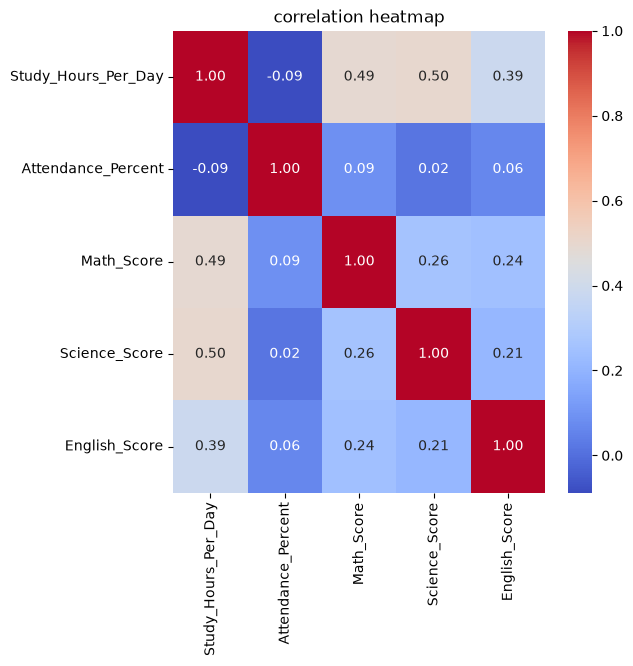

In [35]:
"""correlation of heat map """
plt.figure(figsize=(6,6))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("correlation heatmap")
plt.show

result
pass     494
fail       6
Name: count, dtype: int64


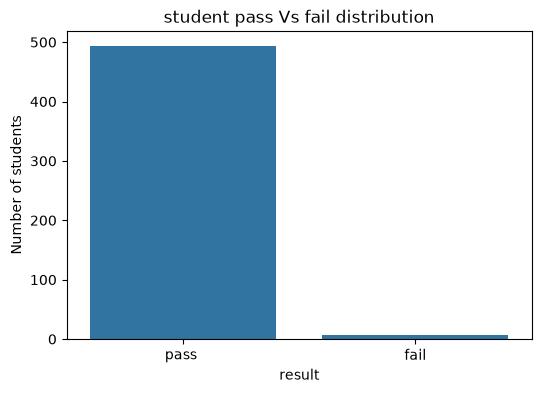

In [37]:
"""pass vs fail distribution in each subject"""
pass_mark=35
df["result"]=df["Math_Score"].apply(
    lambda marks:"pass "if marks>=pass_mark else"fail"
)
print(df["result"].value_counts())
plt.figure(figsize=(6,4))
sns.countplot(data=df,x="result")
plt.title("student pass Vs fail distribution")
plt.xlabel("result")
plt.ylabel("Number of students")
plt.show()

result
pass     497
fail       3
Name: count, dtype: int64


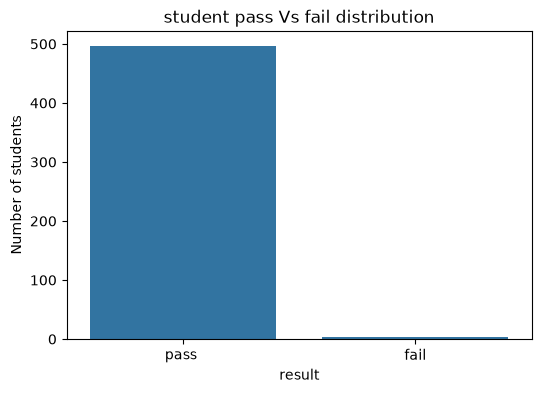

In [38]:
"""pass vs fail distribution in science subject"""
pass_mark=35
df["result"]=df["Science_Score"].apply(
    lambda marks:"pass "if marks>=pass_mark else"fail"
)
print(df["result"].value_counts())
plt.figure(figsize=(6,4))
sns.countplot(data=df,x="result")
plt.title("student pass Vs fail distribution")
plt.xlabel("result")
plt.ylabel("Number of students")
plt.show()

result
pass     498
fail       2
Name: count, dtype: int64


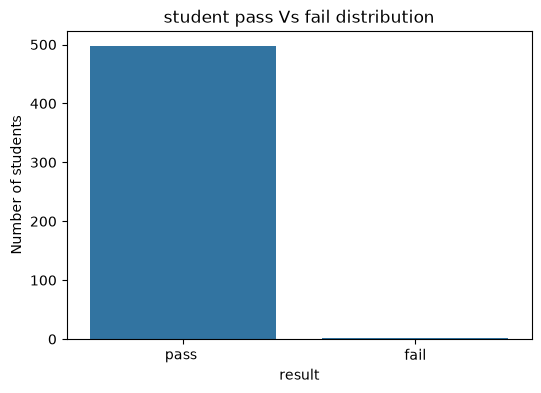

In [39]:
"""pass vs fail distribution in english subject"""
pass_mark=35
df["result"]=df["English_Score"].apply(
    lambda marks:"pass "if marks>=pass_mark else"fail"
)
print(df["result"].value_counts())
plt.figure(figsize=(6,4))
sns.countplot(data=df,x="result")
plt.title("student pass Vs fail distribution")
plt.xlabel("result")
plt.ylabel("Number of students")
plt.show()

In [ ]:
#calculating total and avg marks for each subject
subjects = ["Math_Score", "Science_Score", "English_Score"]

df["Total_Marks"] = df[subjects].sum(axis=1)

df["Average_Marks"] = df[subjects].mean(axis=1)

df[["Total_Marks", "Average_Marks"]].head()

,Total_Marks,Average_Marks
0,200,66.666667
1,228,76.000000
2,229,76.333333
3,249,83.000000
4,143,47.666667


In [44]:

def assign_grade(marks):
    if pd.isna(marks):
        return pd.NA
    elif marks >= 90:
        return "A+"
    elif marks >= 80:
        return "A"
    elif marks >= 70:
        return "B"
    elif marks >= 60:
        return "C"
    elif marks >= 50:
        return "D"
    elif marks >= 35:
        return "E"
    else:
        return "F"

df["Grade"] = df["Average_Marks"].apply(assign_grade)

print(df["Grade"].value_counts().reindex(
    ["A+", "A", "B", "C", "D", "E", "F"],
    fill_value=0
))

Grade
A+     10
A      75
B     178
C     155
D      70
E      12
F       0
Name: count, dtype: int64


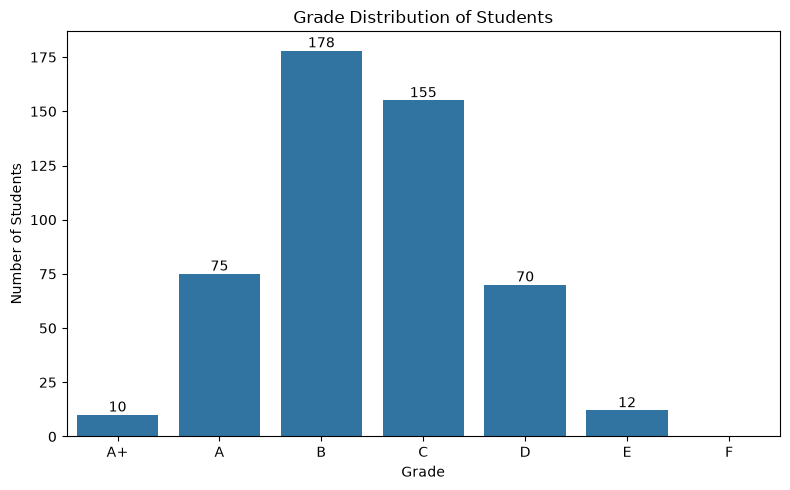

In [45]:
"""grade visualization"""
grade_order = ["A+", "A", "B", "C", "D", "E", "F"]

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Grade",
    order=grade_order
)

ax.bar_label(ax.containers[0])

plt.title("Grade Distribution of Students")
plt.xlabel("Grade")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()



In [ ]:
# analyse subject wise performance
subject_averages = df[subjects].mean()

print("Average marks by subject:")
print(subject_averages)

print("\nHighest average:", subject_averages.idxmax())
print("Lowest average:", subject_averages.idxmin())

Average marks by subject:
Math_Score       68.440
Science_Score    70.296
English_Score    72.156
dtype: float64

Highest average: English_Score
Lowest average: Math_Score


In [47]:
"""analyse top and low performing students"""
top_students = df.sort_values(
    by="Average_Marks",
    ascending=False
).head(5)

print(top_students)


    Student_ID   Student_Name  Study_Hours_Per_Day  Attendance_Percent  \
275    STU0276    Pooja Gupta                  8.1                  85   
436    STU0437  Aditya Pillai                  5.0                  84   
270    STU0271    Meera Gupta                  7.8                  59   
419    STU0420   Ishita Gupta                  5.7                 100   
333    STU0334  Tejaswini Rao                  7.0                  64   

     Math_Score  Science_Score  English_Score performance_level result  \
275         100            100            100         excellent  pass    
436          96            100             87         excellent  pass    
270         100             90             89         excellent  pass    
419          83             96             99              good  pass    
333          88             95             94         excellent  pass    

     Total_Marks  Average_Marks Grade  
275          300     100.000000    A+  
436          283      94.33333

In [48]:
top_students = df.sort_values(
    by="Average_Marks",
    ascending=True
).head(5)

print(top_students)

    Student_ID      Student_Name  Study_Hours_Per_Day  Attendance_Percent  \
88     STU0089       Neha Pillai                  3.3                  83   
209    STU0210         Kiran Das                  2.3                  72   
440    STU0441       Varun Kumar                  1.1                  63   
282    STU0283  Aditya Chowdhury                  1.8                  86   
60     STU0061       Anirudh Rao                  0.3                  90   

     Math_Score  Science_Score  English_Score performance_level result  \
88           51             19             51           average  pass    
209          41             50             33              pass   fail   
440          49             33             54              pass  pass    
282          51             53             33           average   fail   
60           45             46             52              pass  pass    

     Total_Marks  Average_Marks Grade  
88           121      40.333333     E  
209         

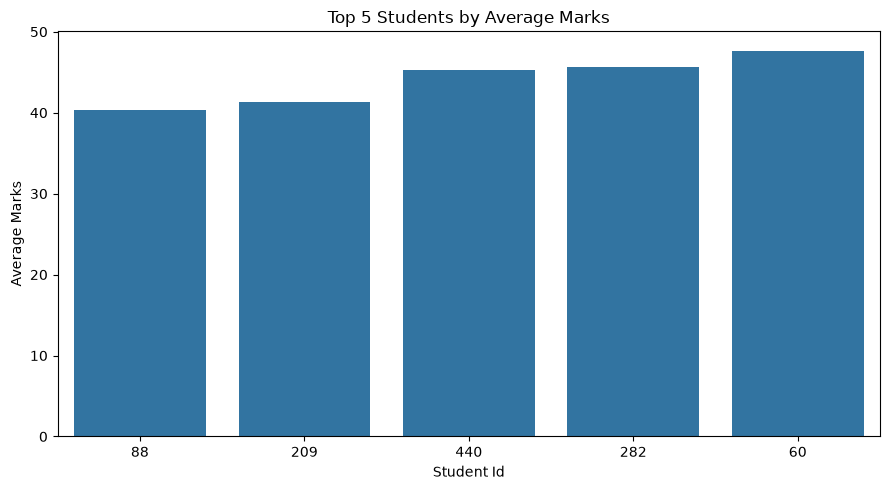

In [50]:
"""visualize top 5 students"""

plt.figure(figsize=(9, 5))

sns.barplot(
    data=top_students,
    x=top_students.index.astype(str),
    y="Average_Marks"
)

plt.title("Top 5 Students by Average Marks")
plt.xlabel("Student Id")
plt.ylabel("Average Marks")

plt.tight_layout()
plt.show()

In [51]:
"""calculating overall performance statstics"""
print("Class average:", round(df["Average_Marks"].mean(), 2))
print("Highest average:", round(df["Average_Marks"].max(), 2))
print("Lowest average:", round(df["Average_Marks"].min(), 2))
print("Median average:", round(df["Average_Marks"].median(), 2))

Class average: 70.3
Highest average: 100.0
Lowest average: 40.33
Median average: 70.67


In [52]:
#insights 
subjects = ["Math_Score", "Science_Score", "English_Score"]

print("STUDENT PERFORMANCE REPORT")
print("-" * 35)

print("Total students:", len(df))

print("\nSubject-wise averages:")
print(df[subjects].mean().round(2))

print("\nOverall class average:",
      round(df["Average_Marks"].mean(), 2))

print("Highest student average:",
      round(df["Average_Marks"].max(), 2))

print("Lowest student average:",
      round(df["Average_Marks"].min(), 2))

print("\nGrade distribution:")
print(df["Grade"].value_counts().sort_index())


STUDENT PERFORMANCE REPORT
-----------------------------------
Total students: 500

Subject-wise averages:
Math_Score       68.44
Science_Score    70.30
English_Score    72.16
dtype: float64

Overall class average: 70.3
Highest student average: 100.0
Lowest student average: 40.33

Grade distribution:
Grade
A      75
A+     10
B     178
C     155
D      70
E      12
Name: count, dtype: int64


In [54]:
#calucalting  high performing subjects and low performing subjects
subject_avg = df[subjects].mean()

print("highest performing subject:", subject_avg.idxmax())
print("Needs attention:", subject_avg.idxmin())

highest performing subject: English_Score
Needs attention: Math_Score


In [55]:
#calculating grade percentages
grade_counts = df["Grade"].value_counts()

grade_percentages = (
    grade_counts / df["Grade"].notna().sum()
) * 100

print(grade_percentages.round(2))

Grade
B     35.6
C     31.0
A     15.0
D     14.0
E      2.4
A+     2.0
Name: count, dtype: float64


# Conclusion

The Student Performance Analysis project was conducted to understand students' academic performance in **Mathematics, Science, and English** using Python.

Data cleaning and exploratory data analysis were performed using Pandas and NumPy. Matplotlib and Seaborn were used to visualize student performance through bar charts, box plots, a correlation heatmap, and grade distribution charts.

The analysis helped compare subject-wise average marks, examine variations in student scores, identify potential outliers, and understand relationships between subject scores. The grade distribution provided an overview of students' academic achievement.

Overall, this project demonstrates how data analysis and visualization can help identify academic strengths and areas that may require additional support. These insights can help teachers and schools make informed decisions to support student learning and improve academic outcomes.